# Homework 6B - Visual Encoding
## Shivali Mate
In this assignment, you will explore how to encode different data features to visual properties using the movies dataset located in `Datasets/movies.json`. 

We will start with simpler visualizations and then move to more complex (and potentially cluttered) visualizations. Finally, you will create a focused visualization that uses only a few selected encodings.

## Instructions

The assignment is divided into three parts:

1. **Project Setup**:  

   - Set up your Python and Jupyter (or VSCode) environment.  

   - Clone or download the repository provided in class (refer to the class notes).

2. **Simple Visualizations:** Create basic visualizations using one or two encodings.

3. **Cluttered Visualization:** Create a visualization that encodes many features simultaneously.

4. **Focused Visualization:** Create one or more visualizations using a few chosen encodings, and discuss your design choices.

5. **Documentation**:  

   - Comment your code and add markdown explanations for each part of your analysis.

6. **Submission**:  

   - Save your notebook and export as either PDF or HTML. If the visualization is not shown in the html, submit a separated version with altair html. Refer to: https://altair-viz.github.io/getting_started/starting.html#publishing-your-visualization (you can use the `chart.save('chart_file.html')` method).
   - Submit to Canvas.



You are free to use any libraries you prefer for visualization, but we recommend using `matplotlib`, `seaborn`, and/or `altair` for this assignment.

   

Happy coding and visualizing!

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import altair as alt

# If you're running in a notebook environment that limits rows for interactive charts:
alt.data_transformers.disable_max_rows()

# Read the dataset
df = pd.read_json("movies.json")
df.head()

# Let's create a new column for the ratio of US Gross to Production Budget
df['US Gross to Production Budget'] = df['US Gross'] / df['Production Budget']


## Part 0: Simple Visualizations



In this section, you will build simple plots that use minimal visual encodings. This will help you get comfortable with basic mappings before adding complexity.



### Task 0.1: Simple Scatterplot

Create a basic scatterplot that maps:

- **x-axis:** `Production Budget`

- **y-axis:** `US Gross`



*Hint:* You can use:

- `plt.scatter()` from `matplotlib`

- `sns.scatterplot()` from `seaborn`

- `alt.Chart()` from `altair` with `mark_point()`



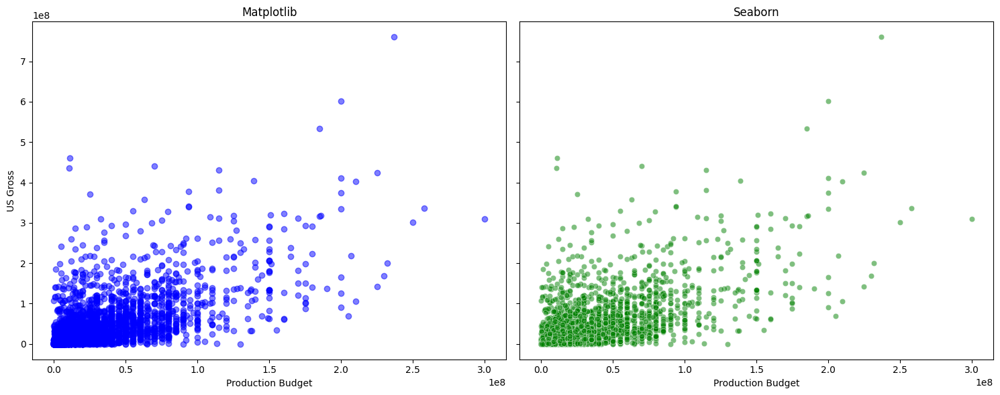

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

axes[0].scatter(df['Production Budget'], df['US Gross'], color='blue', alpha=0.5)
axes[0].set_title('Matplotlib')
axes[0].set_xlabel('Production Budget')
axes[0].set_ylabel('US Gross')

sns.scatterplot(x='Production Budget', y='US Gross', data=df, ax=axes[1], color='green', alpha=0.5)
axes[1].set_title('Seaborn')
axes[1].set_xlabel('Production Budget')
axes[1].set_ylabel('') 

plt.tight_layout()

plt.show()

In [15]:
scatter_plot = alt.Chart(df).mark_point().encode(
    x=alt.X("Production Budget:Q", axis=alt.Axis(title="Production Budget")),
    y=alt.Y("US Gross:Q", axis=alt.Axis(title="US Gross"))
).properties(
    width=600,  
    height=400,  
    title="Altair Scatter Plot of Production Budget vs US Gross"
)

scatter_plot

alt.Chart(...)

### Task 0.2: Simple Bar Plot

Now, create a bar plot that shows the average `IMDB Rating` for each `Major Genre`.



*Hint:* You can use:

- `plt.bar()` from `matplotlib`

- `sns.barplot()` from `seaborn`

- `alt.Chart()` from `altair` with `mark_bar()`



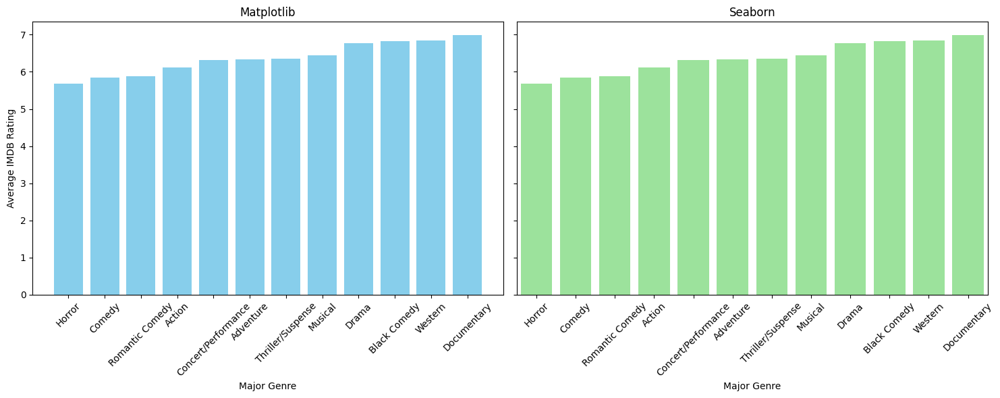

In [16]:
avg_ratings = df.groupby("Major Genre")["IMDB Rating"].mean().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

axes[0].bar(avg_ratings.index, avg_ratings.values, color='skyblue')
axes[0].set_title('Matplotlib')
axes[0].set_xlabel('Major Genre')
axes[0].set_ylabel('Average IMDB Rating')
axes[0].tick_params(axis='x', rotation=45)

sns.barplot(x=avg_ratings.index, y=avg_ratings.values, ax=axes[1], color='lightgreen')
axes[1].set_title('Seaborn')
axes[1].set_xlabel('Major Genre')
axes[1].set_ylabel('')
axes[1].tick_params(axis='x', rotation=45)


plt.tight_layout()

plt.show()

In [17]:
genre_avg_df = avg_ratings.reset_index()

bar_chart = alt.Chart(genre_avg_df).mark_bar().encode(
    x=alt.X("Major Genre:N", sort=alt.SortField("IMDB Rating", order="ascending"), 
            axis=alt.Axis(title="Major Genre")),
    y=alt.Y("IMDB Rating:Q", axis=alt.Axis(title="Average IMDB Rating"))
).properties(
    width=600,  
    height=400,
    title="Altair Bar Plot of Average IMDB Rating by Major Genre"
)

bar_chart

alt.Chart(...)

### 
Task 0.3: Another Simple Scatterplot

Create a basic scatterplot that maps:

- **x-axis:** `IMDB Rating`

- **y-axis:** `US Gross to Production Budget`



*Important*: `US Gross to Production Budget` is a ratio. Thus, you should use the logarithmic scale for the y-axis to better visualize the data.



*Hint:* You can use:

- `plt.yscale('log')` from `matplotlib` (also works with `seaborn`)

- `y=alt.Y('...').scale(type="log")` from `altair`



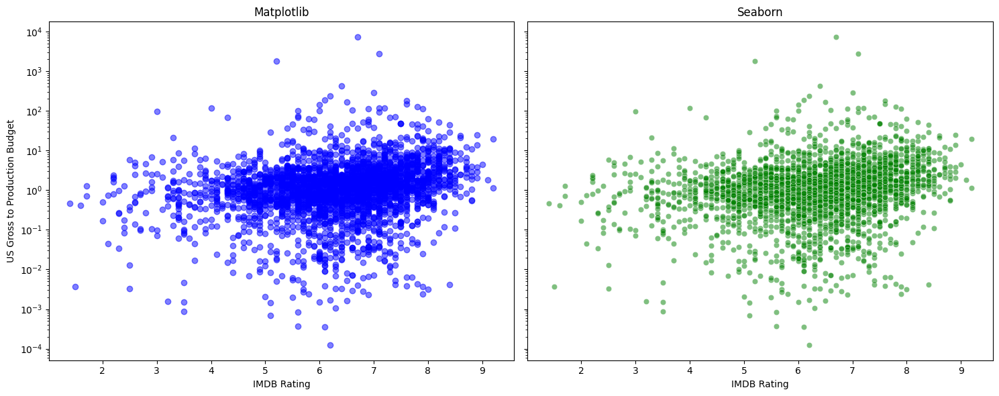

In [18]:
df['US Gross to Production Budget'] = df['US Gross'] / df['Production Budget']

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

axes[0].scatter(df['IMDB Rating'], df['US Gross to Production Budget'], color='blue', alpha=0.5)
axes[0].set_title('Matplotlib')
axes[0].set_xlabel('IMDB Rating')
axes[0].set_ylabel('US Gross to Production Budget')
axes[0].set_yscale('log')

sns.scatterplot(x='IMDB Rating', y='US Gross to Production Budget', data=df, ax=axes[1], color='green', alpha=0.5)
axes[1].set_title('Seaborn')
axes[1].set_xlabel('IMDB Rating')
axes[1].set_ylabel('')
axes[1].set_yscale('log')

plt.tight_layout()

plt.show()

In [19]:
df_filtered = df[df["US Gross to Production Budget"] > 0]

scatter_plot = alt.Chart(df_filtered).mark_point().encode(
    x=alt.X("IMDB Rating:Q", axis=alt.Axis(title="IMDB Rating")),
    y=alt.Y("US Gross to Production Budget:Q", 
            scale=alt.Scale(type="log", domain=[df_filtered["US Gross to Production Budget"].min(), df_filtered["US Gross to Production Budget"].max()]), 
            axis=alt.Axis(title="US Gross to Production Budget (Log Scale)"))
).properties(
    width=600, 
    height=400, 
    title="Altair Scatter Plot of IMDB Rating vs US Gross to Production Budget"
)

scatter_plot

alt.Chart(...)

### Task 0.4 : Another Simple Bar Plot

Create a bar plot that shows the average `US Gross to Production Budget` for each `Major Genre`.



Remember to use the logarithmic scale for the y-axis to better visualize the data.



What are the insights you can draw from this plot?

In [20]:
bar_chart = alt.Chart(df_filtered).mark_bar().encode(
    x=alt.X("Major Genre:N", sort="-y", axis=alt.Axis(title="Major Genre")),
    y=alt.Y("mean(US Gross to Production Budget):Q",
            scale=alt.Scale(type="log"),
            axis=alt.Axis(title="Average US Gross to Production Budget (Log Scale)"))
).properties(
    width=600,
    height=400,
    title="Altair Bar Plot of Average US Gross to Production Budget by Major Genre"
)

bar_chart


alt.Chart(...)

Your comments and insights here:

Any interesting observations from any of the plots you created so far?

## Comments and Insights for Altair Scatter Plot of IMDB Rating vs US Gross to Production Budget 

- *Wide Distribution of Movies*: The plot shows a broad range of movies, with varying IMDb ratings and US Gross to Production Budget ratios. There is a significant dispersion of data points, suggesting that while many movies perform similarly in terms of their budget-to-gross ratio, there are also movies with outlier performances.

- *No Clear Trend*: The lack of a distinct upward or downward trend indicates that IMDb ratings are not strongly correlated with the US Gross to Production Budget. This suggests that a higher IMDb rating doesn't necessarily translate to a higher return on investment (as measured by the US Gross to Production Budget).

- *Logarithmic Scale Impact*: The use of a logarithmic scale for the y-axis highlights the large disparities in the US Gross to Production Budget ratio, especially for movies with low ratios. This allows us to better observe the spread of data for movies with small budget-to-gross ratios.

- *Clustered Data Points*: Many of the data points are clustered around the middle range of IMDb ratings (4–6). This suggests that most movies, regardless of budget, tend to have average ratings within this range.

- *Outliers*: A small number of movies with exceptionally high ratios (large US Gross relative to their production budget) appear as isolated points on the upper-right side of the chart. These are likely blockbuster or highly profitable films with relatively low budgets, potentially within the *Documentary* or *Horror* genres.

## Part 1: Intermediate Visual Encodings



Now that you have built simple plots, let's gradually add more visual encodings.



### Task 1.1: Adding Color

Extend one of the scatterplots from Tasks 0.1 or 0.3 by encoding:

- **Color** to `MPAA Rating`



*Hint:* You can use the `hue` parameter in `seaborn` or the `color` parameter in `matplotlib`.

*Note:* You can also use `alt.Chart()` with `encode(color='MPAA Rating')` for color encoding.



Complete the code cell below.

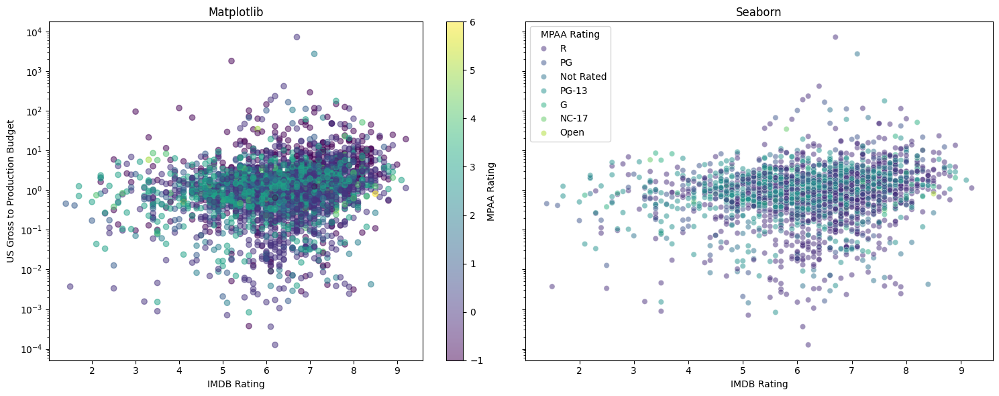

In [21]:
# Fill Code Here
df['US Gross to Production Budget'] = df['US Gross'] / df['Production Budget']

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

scatter = axes[0].scatter(df['IMDB Rating'], df['US Gross to Production Budget'], c=pd.factorize(df['MPAA Rating'])[0], cmap='viridis', alpha=0.5)
axes[0].set_title('Matplotlib')
axes[0].set_xlabel('IMDB Rating')
axes[0].set_ylabel('US Gross to Production Budget')
axes[0].set_yscale('log')
plt.colorbar(scatter, ax=axes[0], label='MPAA Rating')

sns.scatterplot(x='IMDB Rating', y='US Gross to Production Budget', hue='MPAA Rating', data=df, ax=axes[1], palette='viridis', alpha=0.5)
axes[1].set_title('Seaborn')
axes[1].set_xlabel('IMDB Rating')
axes[1].set_ylabel('')
axes[1].set_yscale('log')

plt.tight_layout()

plt.show()


### Task 1.2: Adding Size

Further extend the scatterplot by encoding another feature:

- **Size** to e.g. `Running Time min`, `IMDB Votes`




This adds another dimension to the plot. Fill in the code below.

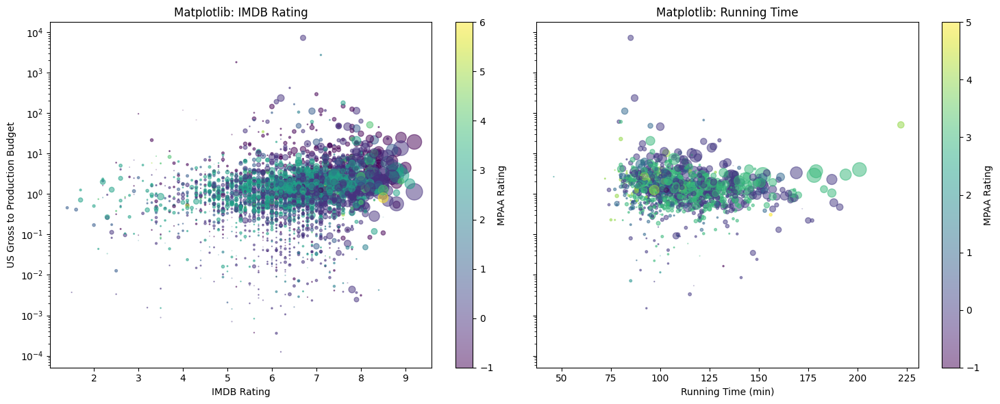

In [22]:
df['US Gross to Production Budget'] = df['US Gross'] / df['Production Budget']
size_votes = df['IMDB Votes'] / df['IMDB Votes'].max() * 300

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

scatter1 = axes[0].scatter(
    df['IMDB Rating'], df['US Gross to Production Budget'],
    c=pd.factorize(df['MPAA Rating'])[0],
    s=size_votes,
    cmap='viridis',
    alpha=0.5
)
axes[0].set_title('Matplotlib: IMDB Rating')
axes[0].set_xlabel('IMDB Rating')
axes[0].set_ylabel('US Gross to Production Budget')
axes[0].set_yscale('log')
plt.colorbar(scatter1, ax=axes[0], label='MPAA Rating')

scatter2 = axes[1].scatter(
    df['Running Time min'], df['US Gross to Production Budget'],
    c=pd.factorize(df['MPAA Rating'])[0],
    s=size_votes,
    cmap='viridis',
    alpha=0.5
)
axes[1].set_title('Matplotlib: Running Time')
axes[1].set_xlabel('Running Time (min)')
axes[1].set_ylabel('')
axes[1].set_yscale('log')
plt.colorbar(scatter2, ax=axes[1], label='MPAA Rating')

plt.tight_layout()
plt.show()


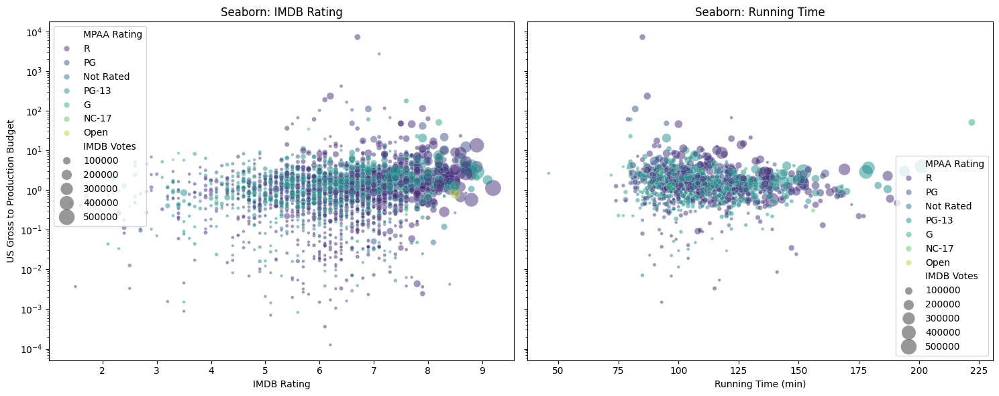

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

sns.scatterplot(
    x='IMDB Rating',
    y='US Gross to Production Budget',
    hue='MPAA Rating',
    size='IMDB Votes',
    sizes=(10, 300),
    data=df,
    palette='viridis',
    alpha=0.5,
    ax=axes[0]
)
axes[0].set_title('Seaborn: IMDB Rating')
axes[0].set_xlabel('IMDB Rating')
axes[0].set_ylabel('US Gross to Production Budget')
axes[0].set_yscale('log')

sns.scatterplot(
    x='Running Time min',
    y='US Gross to Production Budget',
    hue='MPAA Rating',
    size='IMDB Votes',
    sizes=(10, 300),
    data=df,
    palette='viridis',
    alpha=0.5,
    ax=axes[1]
)
axes[1].set_title('Seaborn: Running Time')
axes[1].set_xlabel('Running Time (min)')
axes[1].set_ylabel('')
axes[1].set_yscale('log')

plt.tight_layout()
plt.show()



In [24]:
df["size_votes"] = df["IMDB Votes"] / df["IMDB Votes"].max() * 300
df_filtered = df[df["US Gross to Production Budget"] > 0]

chart1 = alt.Chart(df_filtered).mark_circle(opacity=0.5).encode(
    x=alt.X("IMDB Rating:Q"),
    y=alt.Y("US Gross to Production Budget:Q", scale=alt.Scale(type="log")),
    size=alt.Size("size_votes:Q", title="IMDB Votes (Scaled)"),
    color=alt.Color("MPAA Rating:N"),
    tooltip=["IMDB Rating", "US Gross to Production Budget", "MPAA Rating", "IMDB Votes"]
).properties(
    width=300,
    height=400,
    title="Altair: IMDB Rating vs US Gross to Production Budget"
)


chart2 = alt.Chart(df_filtered).mark_circle(opacity=0.5).encode(
    x=alt.X("Running Time min:Q", title="Running Time (min)"),
    y=alt.Y("US Gross to Production Budget:Q", scale=alt.Scale(type="log")),
    size=alt.Size("size_votes:Q", title="IMDB Votes (Scaled)"),
    color=alt.Color("MPAA Rating:N"),
    tooltip=["Running Time min", "US Gross to Production Budget", "MPAA Rating", "IMDB Votes"]
).properties(
    width=300,
    height=400,
    title="Altair: Running Time vs US Gross to Production Budget"
)



(chart1 | chart2).resolve_scale(y='shared')



alt.HConcatChart(...)

## Part 2: Cluttered Visualization

The next task is to create a visualization that encodes as many features as possible. Try mapping:



- **Color**

- **Size**

- **Shape/Marker**

- **Position**

- **Transparency (alpha)**

- **Any other visual property you can think of?**



*Note:* The goal is to demonstrate how quickly a visualization can become cluttered when too many encodings are used.

You are free to choose any combination of the above encodings. Do your worst!

Fill in the code below with your own choices for mappings.

In [25]:
# Fill Code Here

df_filtered = df[df["US Gross to Production Budget"] > 0].copy()

df_filtered["size_votes"] = df_filtered["IMDB Votes"] / df_filtered["IMDB Votes"].max() * 300
shape_map = df_filtered["MPAA Rating"].astype("category")
if shape_map.nunique() > 5:
    top_shapes = shape_map.value_counts().nlargest(5).index
    df_filtered = df_filtered[df_filtered["MPAA Rating"].isin(top_shapes)]

chart = alt.Chart(df_filtered).mark_point(filled=True).encode(
    x=alt.X("Running Time min:Q", title="Running Time (min)"),
    y=alt.Y("US Gross to Production Budget:Q", scale=alt.Scale(type="log"), title="US Gross / Production Budget (log)"),
    color=alt.Color("Major Genre:N"),
    size=alt.Size("size_votes:Q", title="IMDB Votes (scaled)"),
    shape=alt.Shape("MPAA Rating:N"),
    opacity=alt.Opacity("IMDB Rating:Q", scale=alt.Scale(domain=[0, 10])),
    tooltip=[
        "Title:N", "Major Genre:N", "MPAA Rating:N", "IMDB Rating:Q",
        "Running Time min:Q", "US Gross to Production Budget:Q"
    ]
).properties(
    width=700,
    height=500,
    title="Visual Overload with Many Encodings"
)

chart


alt.Chart(...)

## Part 3: Focused Visualization



For the final part, create more visualizations that use only a few well-chosen encodings in each. For example, you might decide to just use 3 encodings (2 positions + color, or two positions + size, or color + size + shape).

- Map **color** 

- Map **size**

- Use **position (X,Y)** 



Create a few different visualizations maintaining x and y positions, but changing the color, size, or shape encodings, to showcase different aspects of the data.



You can also use redundant encodings, e.g., using both color and shape to represent the same feature.

This will help you focus on the most important aspects of the data without overwhelming the viewer with too much information.



After creating the visualization, write a brief discussion (just a few sentences) in the markdown cell that follows. Explain:

- Why you selected these specific encodings.

- How these choices improve interpretability.

- Any trade-offs involved in reducing the number of encoded features.

In [26]:
# Your code here
chart_color = alt.Chart(df_filtered).mark_circle(opacity=0.6).encode(
    x=alt.X("IMDB Rating:Q"),
    y=alt.Y("US Gross to Production Budget:Q", scale=alt.Scale(type="log")),
    color=alt.Color("Major Genre:N", legend=alt.Legend(title="Genre")),
    tooltip=["Title:N", "Major Genre:N", "IMDB Rating:Q", "US Gross to Production Budget:Q"]
).properties(
    width=600,
    height=400,
    title="IMDB Rating vs ROI (Color by Genre)"
)

chart_color

alt.Chart(...)

In [27]:
chart_size = alt.Chart(df_filtered).mark_circle(color="steelblue", opacity=0.5).encode(
    x=alt.X("IMDB Rating:Q"),
    y=alt.Y("US Gross to Production Budget:Q", scale=alt.Scale(type="log")),
    size=alt.Size("IMDB Votes:Q", title="IMDB Votes"),
    tooltip=["Title:N", "IMDB Rating:Q", "IMDB Votes:Q", "US Gross to Production Budget:Q"]
).properties(
    width=600,
    height=400,
    title="IMDB Rating vs ROI (Size by IMDB Votes)"
)

chart_size

alt.Chart(...)

In [28]:
top_ratings = df_filtered["MPAA Rating"].value_counts().nlargest(5).index
df_filtered_top_ratings = df_filtered[df_filtered["MPAA Rating"].isin(top_ratings)]

chart_shape_color = alt.Chart(df_filtered_top_ratings).mark_point(opacity=0.6).encode(
    x=alt.X("IMDB Rating:Q"),
    y=alt.Y("US Gross to Production Budget:Q", scale=alt.Scale(type="log")),
    shape=alt.Shape("MPAA Rating:N"),
    color=alt.Color("MPAA Rating:N"),
    tooltip=["Title:N", "MPAA Rating:N", "IMDB Rating:Q", "US Gross to Production Budget:Q"]
).properties(
    width=600,
    height=400,
    title="IMDB Rating vs ROI (Redundant Encoding: Shape & Color by MPAA Rating)"
)

chart_shape_color

alt.Chart(...)

### Discussion



Please write your reflections here:



- Why did you choose the specific encodings for the focused visualization?

- How do the selected visual properties (color, size, position) help in understanding the data better?

- What improvements in clarity do you observe compared to the cluttered visualization?

- What trade-offs do you notice when reducing the number of encoded features?



Use this cell to provide a brief explanation of your design decisions.

## Reflections on Focused Visualization

### 1. Reasons for Choosing Specific Encodings
   - In the first chart, I used color to represent the movie genre (Major Genre) in order to easily differentiate movies from various genres. This helps viewers recognize patterns and outliers for each genre more effectively.
   - In the second chart, size was used to represent the number of IMDB Votes, which highlights the popularity of movies based on how many votes they have received. This encoding also shows how the return on investment varies across movies with different levels of audience involvement.
   - For the third chart, I used both shape and color to represent MPAA Rating, employing redundant encoding to make the feature clearer and easier to interpret. This method helps viewers distinguish between the various MPAA ratings more effectively.

### 2. How the Chosen Visual Features Aid Understanding
   - Using color helps viewers quickly tell movies apart by genre, which makes it easier to identify trends within each genre regarding their return on investment.
   - The size encoding helps visualize the connection between IMDB Votes and the US Gross to Production Budget. Larger circles represent more popular movies, which directly communicates how popularity (as measured by votes) relates to the financial success of the movies.
   - The use of both shape and color to depict MPAA Rating enhances the clarity of this feature, as viewers can easily differentiate between different ratings based on the shape and color of the points.

### 3. Benefits of Reducing Clutter
   - By limiting the number of encodings, I reduced visual clutter, allowing viewers to focus on the essential elements of the data. Using color for genre and size for votes simplifies the chart, making it easier to observe key trends without overwhelming the viewer with too much information.
   - The initial scatter plot, which included many features, was harder to interpret due to its lack of clear groupings. By reducing the visual complexity, I made it easier to identify and analyze the most important aspects of the data.

### 4. Trade-offs of Simplifying the Visualization
   - While simplifying the visualization by reducing the number of encodings improves clarity, it also means that some additional details are not shown. For instance, by focusing on IMDB Rating and US Gross to Production Budget, we lose insights into other aspects like genre that could have been highlighted with additional encodings.
   - There is a balance between keeping the chart simple and including more details. A simpler chart is easier to understand but might miss some deeper insights, whereas adding more encodings can reveal more complex relationships but could potentially make the visualization harder to read.